# Active GLiNER: Slot filling to JSON

The task: turn a voice command into JSON slots. For example, *"wake me up at 7 am tomorrow"* gives `{"time": ["7 am"], "date": ["tomorrow"]}`.

This notebook follows the recipe from the paper:

```
your unlabelled texts
   │  1. the untrained student ranks them once, least sure first
   ▼
top N texts ──> a random quarter: human labels
           └──> the rest: LLM labels
   │  2. train the student on both (LoRA)
   ▼
a small, fast model you own ──> 3. check it on labelled dev data ──> 4. predict
```

Data: MASSIVE 1.1 English: voice-assistant commands, 55 slot types. The "human" labels here come from the dataset's own annotators, so you
can see the recipe end to end without labelling anything yourself.

You need a GPU (8 GB is enough) and an OpenAI-compatible LLM server. This repository
starts Gemma 4 12B with `scripts/serve_teacher_gemma.sh`; any other local or hosted
endpoint works too.

In [1]:
import json
from pathlib import Path

import torch
from IPython.display import Image, Markdown, display

from active_gliner import byod, data, tasks

TASK = "slots"
DATASET = "massive"
TEACHER_URL = "http://127.0.0.1:8020/v1"
TEACHER_MODEL = "gemma-4-12b-qat"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 3090


## 1. Your data

The tool reads JSONL files, one text per line:

+ `texts.jsonl` - unlabelled texts (`text`, and for relations the `entities` list).
+ `dev.jsonl` - a few hundred texts with correct labels, to measure accuracy.

Here we write both from the dataset.

In [2]:
demo = Path("demo-slots")
demo.mkdir(exist_ok=True)
splits = data.load(DATASET)
names = tasks.labels(DATASET, splits)  # label code -> label name


def write(path, records, with_labels):
    rows = [byod.record_to_row(r, names, with_labels) for r in records]
    path.write_text("".join(json.dumps(row, ensure_ascii=False) + "\n" for row in rows))


write(demo / "texts.jsonl", splits["pool"][:5000], with_labels=False)
write(demo / "dev.jsonl", splits["dev"][:300], with_labels=True)
labels = ",".join(names.values())
print(len(names), "labels:", labels[:200], "...")
print(open(demo / "dev.jsonl").readline()[:300])

55 labels: alarm type,app name,artist name,audiobook author,audiobook name,business name,business type,change amount,coffee type,color type,cooking type,currency name,date,definition word,device type,drink type, ...
{"id": "massive:en-US:11", "text": "turn the lights off please", "entities": []}



## 2. What the untrained student does

GLiNER2.5 already works for any label names, with no training. This is the score to beat.

In [3]:
task = tasks.for_dataset(DATASET)
dev = byod.read_labelled(demo / "dev.jsonl", TASK)
label_map = byod.parse_labels(labels)
student = byod.load_student(TASK, label_map)
zero_shot_f1 = task.score(dev, task.predict(student, dev, label_map), label_map)["micro"]["f1"]
print(f"Zero-shot dev F1: {100 * zero_shot_f1:.1f}")
del student
torch.cuda.empty_cache()

Zero-shot dev F1: 25.4


## 3. Rank once and split between humans and the LLM

`rank` scores every text with the untrained student, takes the 1,000 it is least sure
about (texts where it finds nothing go last), and puts a random quarter of them in
`for_humans.jsonl`. The rest goes in `for_llm.jsonl`.

From a terminal:

```bash
active-gliner rank --texts demo/texts.jsonl --task slots --labels "..." \
  --n 1000 --human-share 0.25 --out demo/rank
```

In [4]:
ranked = byod.rank(
    demo / "texts.jsonl", TASK, labels, n=1000, human_share=0.25, out_dir=demo / "rank"
)
for_humans = [json.loads(line) for line in (ranked / "for_humans.jsonl").open()]
for_llm = [json.loads(line) for line in (ranked / "for_llm.jsonl").open()]
print(len(for_humans), "texts for humans,", len(for_llm), "for the LLM")
print("example for a human:", for_humans[0]["text"][:200])

250 texts for humans, 750 for the LLM
example for a human: what's a silly joke you know


## 4. Human labels

In real use, people label `for_humans.jsonl` by hand, in the same format as `dev.jsonl`.
Here we copy the dataset's own labels for those texts.

In [5]:
by_id = {r.id: r for r in splits["pool"]}
write(demo / "human.jsonl", [by_id[row["id"]] for row in for_humans], with_labels=True)
print(open(demo / "human.jsonl").readline()[:300])

{"id": "massive:en-US:492", "text": "what's a silly joke you know", "entities": [{"text": "silly", "start": 9, "end": 14, "label": "joke type"}]}



## 5. LLM labels for the rest, then train

`fit` sends every text in `for_llm.jsonl` to the LLM (`select="all"`), checks every
answer (valid JSON, allowed labels, exact text spans), adds the human-labelled texts,
and trains a LoRA adapter. The LLM never sees the human-labelled texts.

```bash
active-gliner fit --texts demo/rank/for_llm.jsonl --select all --human demo/human.jsonl \
  --task slots --labels "..." --dev demo/dev.jsonl \
  --teacher-url http://127.0.0.1:8020/v1 --teacher-model gemma-4-12b-qat --out demo/run
```

For a hosted API, also pass `api_key_env="NAME_OF_THE_KEY_VARIABLE"`.

In [6]:
run = byod.fit(
    texts=ranked / "for_llm.jsonl",
    task=TASK,
    labels=labels,
    teacher_url=TEACHER_URL,
    teacher_model=TEACHER_MODEL,
    select="all",
    human=demo / "human.jsonl",
    dev=demo / "dev.jsonl",
    out_dir=demo / "run",
)
print(run)

demo-slots/run


## 6. Check the result

Every run folder holds plain files: a one-page report, training curves, every LLM label
and every wrong prediction.

In [7]:
metrics = json.loads((run / "metrics.json").read_text())
trained_f1 = metrics["dev"]["micro"]["f1"]
print(f"Dev F1: zero-shot {100 * zero_shot_f1:.1f} -> trained {100 * trained_f1:.1f}")
print("LLM answers:", json.loads((run / "teacher_stats.json").read_text()))

Dev F1: zero-shot 25.4 -> trained 63.6
LLM answers: {'elapsed_s': 229.78053449303843, 'workers': 8, 'gpu_shared': False, 'requests': 750, 'cache_hits': 0, 'retries': 0, 'duplicate': 0, 'prompt_tokens': 1097390, 'completion_tokens': 31522, 'latency_s_total': 1832.9933194292244, 'errors_by_kind': {'overlap_conflict': 61, 'not_on_word_edges': 1}, 'invalid_records': 55, 'valid_rate': 0.9266666666666666, 'cost_usd': 0.0}


In [8]:
display(Markdown((run / "report.md").read_text()))

# user: all, N=750, seed=1

Locale: en-US. Labels: custom. LoRA r=32, alpha=64.0, task LR=0.000348598753479929. Augmentation: False.
Acquisition threshold: 0.5. Evaluation threshold: 0.5.

| Split | Micro F1 | Macro F1 |
| --- | ---: | ---: |
| dev | 0.6359 | 0.4632 |

Best step: 300. Stop reason: early_stopping.
Wall time: 379.01 s. Training time: 110.82 s.

| Type | Precision | Recall | F1 | Support |
| --- | ---: | ---: | ---: | ---: |
| alarm type | 0.0625 | 1.0000 | 0.1176 | 1 |
| app name | 0.0000 | 0.0000 | 0.0000 | 0 |
| artist name | 0.8889 | 0.8421 | 0.8649 | 19 |
| business name | 0.8000 | 1.0000 | 0.8889 | 4 |
| business type | 1.0000 | 1.0000 | 1.0000 | 2 |
| change amount | 0.0000 | 0.0000 | 0.0000 | 5 |
| coffee type | 0.2500 | 1.0000 | 0.4000 | 1 |
| color type | 0.6250 | 0.8333 | 0.7143 | 6 |
| date | 0.8511 | 0.7843 | 0.8163 | 51 |
| device type | 0.7333 | 0.7857 | 0.7586 | 14 |
| event name | 0.5000 | 1.0000 | 0.6667 | 4 |
| food type | 0.7500 | 0.7500 | 0.7500 | 4 |
| general frequency | 0.5000 | 1.0000 | 0.6667 | 1 |
| house place | 0.7143 | 0.8333 | 0.7692 | 12 |
| ingredient | 0.0000 | 0.0000 | 0.0000 | 0 |
| joke type | 0.6000 | 0.7500 | 0.6667 | 4 |
| list name | 0.0000 | 0.0000 | 0.0000 | 0 |
| meal type | 0.0000 | 0.0000 | 0.0000 | 0 |
| media type | 0.5714 | 0.3333 | 0.4211 | 12 |
| music album | 0.0000 | 0.0000 | 0.0000 | 0 |
| music descriptor | 0.1667 | 0.5000 | 0.2500 | 2 |
| music genre | 0.7333 | 0.7333 | 0.7333 | 15 |
| news topic | 0.3030 | 0.9091 | 0.4545 | 11 |
| order type | 0.5833 | 0.8750 | 0.7000 | 8 |
| person | 0.0000 | 0.0000 | 0.0000 | 0 |
| place name | 0.8148 | 0.7097 | 0.7586 | 31 |
| player setting | 0.3636 | 0.6667 | 0.4706 | 6 |
| playlist name | 0.1667 | 0.5000 | 0.2500 | 2 |
| song name | 0.8333 | 0.7143 | 0.7692 | 14 |
| time | 0.5143 | 0.7500 | 0.6102 | 24 |
| time zone | 0.0000 | 0.0000 | 0.0000 | 0 |
| timeofday | 0.5000 | 0.8000 | 0.6154 | 5 |
| transport agency | 0.0000 | 0.0000 | 0.0000 | 0 |
| weather descriptor | 0.5185 | 0.8235 | 0.6364 | 17 |

[Training curves](plots/training_curves.png) · [Calibration](plots/calibration.png) · [Errors](errors.jsonl)

Extraction calibration includes emitted predictions only; low bins can be empty because of the evaluation threshold. Classification includes all label probabilities.


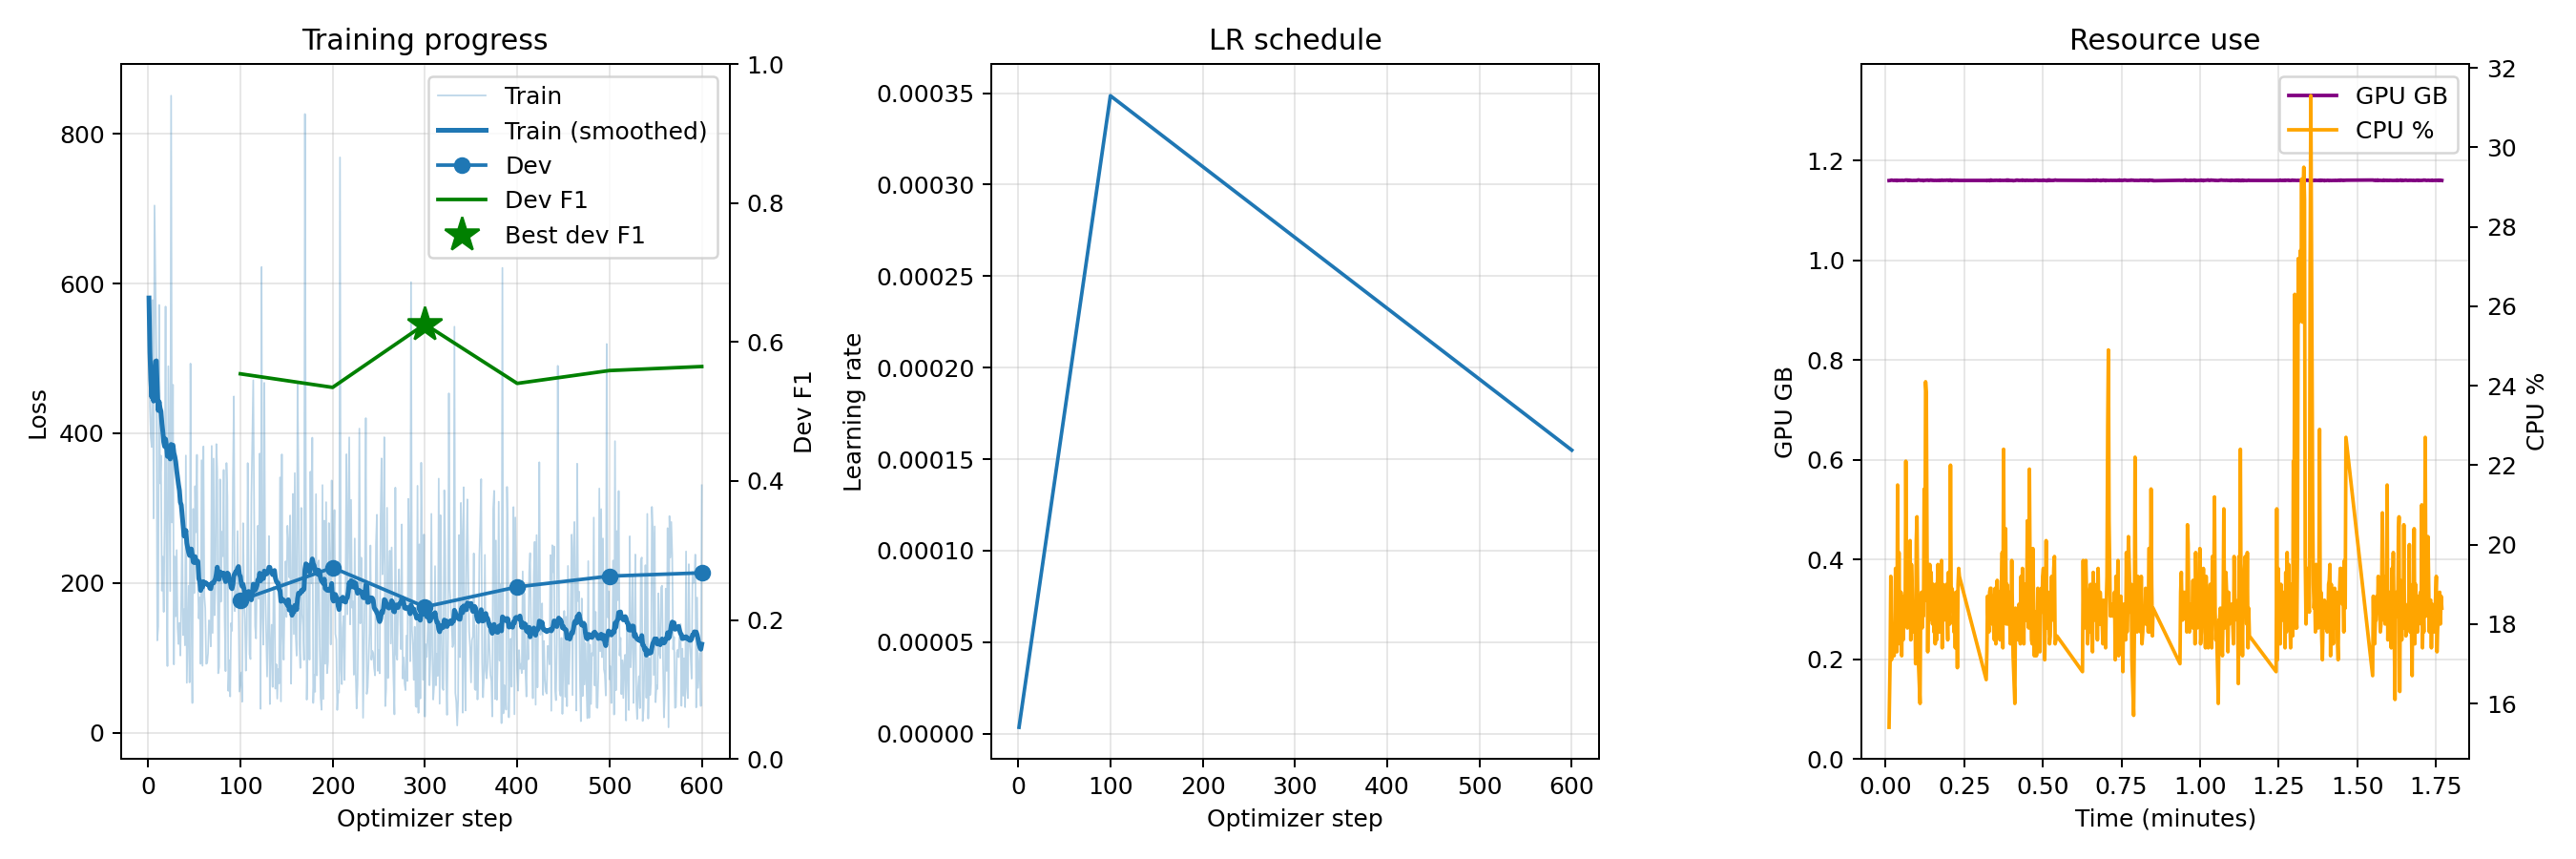

In [9]:
display(Image(filename=str(run / "plots" / "training_curves.png")))

## 7. Use the trained model

`predict` loads the adapter and runs on a GPU or a CPU:

```bash
active-gliner predict --adapter demo/run/adapter/best --task slots --labels "..." \
  --texts new.jsonl
```

In [10]:
new = [
    "wake me up at seven tomorrow morning",
    "play some jazz by miles davis",
    "what is the weather like in paris this weekend",
]
(demo / "new.jsonl").write_text("".join(json.dumps({"text": t}) + "\n" for t in new))
predictions = byod.predict(run / "adapter" / "best", TASK, labels, demo / "new.jsonl")
for text, prediction in zip(new, predictions, strict=True):
    print(text)
    print("   ", [(s["text"], s["label"]) for s in prediction["spans"]])

wake me up at seven tomorrow morning
    [('wake me up', 'alarm type'), ('seven', 'time'), ('tomorrow', 'date'), ('morning', 'timeofday')]
play some jazz by miles davis
    [('jazz', 'music genre'), ('miles davis', 'artist name')]
what is the weather like in paris this weekend
    [('paris', 'place name'), ('this weekend', 'time')]


## What the paper found for this task

Slots tolerate LLM labels the least: the LLM fills slots in most commands that have none, and a quarter of LLM labels already costs about 6 F1 points. Use a larger human share here.

See the paper (`paper/main.pdf`, Section 4.4) for the numbers on every dataset.